# Client Data Analysis Report
**Prepared by:** Thabiso  
**Date:** 17 November 2026  
**Client:** Real Eastate (Proformant )  
**Assessment window:** 17:00–20:00 SAST

---

DB CONNECTION


In [64]:
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres.cxxxmjisggmuohgrozib",
    password="@HelloWord12369$#",
    host="aws-1-eu-central-2.pooler.supabase.com",
    port=6543,
    database="postgres",
    query={"sslmode": "require"}
)

engine = create_engine(url)

with engine.connect() as con:
    print(con.execute(text("SELECT 1")).fetchone())

(1,)


DATA ANALYSIS

In [65]:
#create schema variable
schema = pd.read_sql("""
    SELECT
        table_name,
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_schema = 'public'
    ORDER BY table_name, ordinal_position
""", engine)


#Check avAilable tables
tables = pd.read_sql("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'public'
""", engine)

print(tables)

print('\n--------------Rows in each Table ------------\n')
#rows in each table
tables = pd.read_sql("""
    SELECT table_name FROM information_schema.tables
    WHERE table_schema = 'public'
    AND table_type = 'BASE TABLE'
""", engine)

for table in tables['table_name']:
    count = pd.read_sql(
        f'SELECT COUNT(*) AS total_rows FROM "{table}"',
        engine
    )
    print(f"{table}: {count.iloc[0, 0]} rows")

            table_name
0        PropertyUnits
1         TenantGroups
2         TenantLedger
3              Tenants
4           Properties
5      TurnoverHistory
6  PropertyUnitHistory
7        TurnoverTypes

--------------Rows in each Table ------------

PropertyUnits: 826 rows
TenantGroups: 447 rows
TenantLedger: 74132 rows
Tenants: 1463 rows
Properties: 9 rows
TurnoverHistory: 2158 rows
PropertyUnitHistory: 1109 rows
TurnoverTypes: 83 rows


In [66]:
#investigate table columns

relevant_tables = ["PropertyUnits","Tenants","Properties"]
print(schema[schema['table_name'].isin(relevant_tables)].to_string(index=False))

   table_name             column_name                   data_type
   Properties              PropertyID                        text
   Properties            PropertyName                        text
   Properties                    City                        text
   Properties             LastUpdated                        text
PropertyUnits              PropertyID                        text
PropertyUnits          PropertyUnitID                        text
PropertyUnits            PropertyUnit                        text
PropertyUnits             FloorNumber                        text
PropertyUnits                     GLA                        text
PropertyUnits              MarketRate            double precision
PropertyUnits             LastUpdated                        text
PropertyUnits              UnitTypeID                        text
      Tenants              PropertyID                        text
      Tenants                TenantID                        text
      Tena

In [67]:
#inspect the data  , i need to establish how database represents Active tenants ,Vacated ,primary spaces and additional
for col in ['OccupantStatus', 'AdditionalSpace', 'LeaseStopFlag']:
    print(f"\n--- {col} ---")
    print(pd.read_sql(f"""
        SELECT "{col}", COUNT(*) AS total
        FROM "Tenants"
        GROUP BY "{col}"
        ORDER BY total DESC
    """, engine).to_string(index=False))

print('\n')
#inspect vacate dates
print(pd.read_sql("""
SELECT COUNT(*) AS total_tenants,
    COUNT("LeaseVacateDate") AS with_vacate_date,
    COUNT(*) FILTER (
        WHERE "LeaseVacateDate" IS NULL ) AS without_vacate_date
FROM "Tenants"
""", engine))


--- OccupantStatus ---
OccupantStatus  total
      Inactive    906
       Current    554
           New      3

--- AdditionalSpace ---
AdditionalSpace  total
              Y    765
              N    698

--- LeaseStopFlag ---
LeaseStopFlag  total
            N   1455
            Y      8


   total_tenants  with_vacate_date  without_vacate_date
0           1463               900                  563


In [68]:
#There are 563 tenants without a vacate date ,which ic close to the 554 current
#copare diff indicators as we have tenants who have not yet vacated

comparison = pd.read_sql("""
    SELECT
        "OccupantStatus",
        "LeaseStopFlag",
        CASE
            WHEN "LeaseVacateDate" IS NULL THEN 'Not Vacated'
            ELSE 'Vacated'
        END AS vacate_status,
        COUNT(*) AS total
    FROM "Tenants"
    GROUP BY
        "OccupantStatus",
        "LeaseStopFlag",
        "LeaseVacateDate" IS NULL
    ORDER BY total DESC
""", engine)

print(comparison.to_string(index=False))

OccupantStatus LeaseStopFlag vacate_status  total
      Inactive             N       Vacated    889
       Current             N   Not Vacated    551
      Inactive             N   Not Vacated      9
      Inactive             Y       Vacated      8
       Current             N       Vacated      3
           New             N   Not Vacated      3


In [69]:
#checking duplicates
pd.read_sql("""
    SELECT
        COUNT(*) AS total_active_records,
        COUNT(DISTINCT "TenantID") AS unique_active_tenants,
        COUNT(*) - COUNT(DISTINCT "TenantID") AS duplicate_records
    FROM "Tenants"
    WHERE "LeaseVacateDate" IS NULL
""", engine)


,total_active_records,unique_active_tenants,duplicate_records
0,563,563,0


Q1 Solution

In [70]:
# Active tenants are defined whether they have vacated so condition is where "LeaseVacateDate" IS NULL
q1 = pd.read_sql("""
    SELECT
        p."PropertyName" AS building,
        t."AdditionalSpace",
        COUNT(DISTINCT t."TenantID") AS active_tenants
    FROM "Tenants" t
    JOIN "Properties" p
        ON t."PropertyID" = p."PropertyID"
    WHERE t."LeaseVacateDate" IS NULL
    GROUP BY
        p."PropertyName",
        t."AdditionalSpace"
    ORDER BY
        p."PropertyName",
        t."AdditionalSpace"
""", engine)

q1['Space Type'] = q1['AdditionalSpace'].map({
    'N': 'Primary Space',
    'Y': 'Additional Space'
})

q1 = q1.rename(columns={
    'building': 'Building',
    'active_tenants': 'Active Tenants'
})

q1 = q1[['Building', 'Space Type', 'Active Tenants']]

print(q1.to_string(index=False))




                       Building       Space Type  Active Tenants
                Estuary Offices    Primary Space               2
                Estuary Offices Additional Space               5
Glenelly Mansion Corporate Park    Primary Space              15
Glenelly Mansion Corporate Park Additional Space              33
     Hazel Luxury Retail Centre    Primary Space              25
     Hazel Luxury Retail Centre Additional Space              30
        Palm Dune Retail Centre    Primary Space             125
        Palm Dune Retail Centre Additional Space             103
             Park Ridge Offices    Primary Space               8
             Park Ridge Offices Additional Space               6
        Rivery Lifestyle Centre    Primary Space              19
        Rivery Lifestyle Centre Additional Space              18
           Rivery Retail Centre    Primary Space              49
           Rivery Retail Centre Additional Space              71
        The Docks Retail 

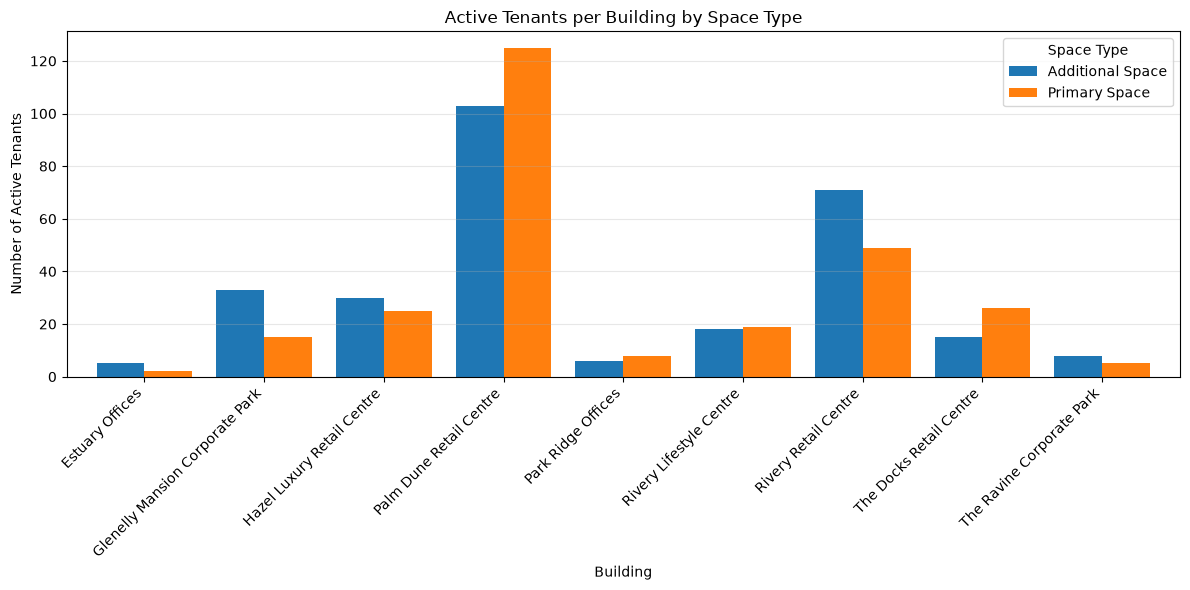

In [71]:
#plot Q1 graph

import matplotlib.pyplot as plt

q1_plot = q1.pivot(
    index='Building',
    columns='Space Type',
    values='Active Tenants'
)

q1_plot.plot(kind='bar', figsize=(12, 6), width=0.8)

plt.title('Active Tenants per Building by Space Type')
plt.xlabel('Building')
plt.ylabel('Number of Active Tenants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Space Type')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Q2 Solution and data analysis

In [72]:
#how is data stored
periods = pd.read_sql("""
    SELECT
        "Period",
        COUNT(*) AS records,
        MIN("ReportDate") AS first_report,
        MAX("ReportDate") AS last_report
    FROM "TurnoverHistory"
    GROUP BY "Period"
    ORDER BY "Period"
""", engine)

print(periods.to_string(index=False))

 Period  records first_report last_report
 202501      197   2025-01-01  2025-03-01
 202502      186   2025-02-01  2025-03-01
 202503      192   2025-03-01  2025-03-03
 202504      178   2024-04-01  2025-04-01
 202505      183   2025-05-01  2025-05-01
 202506      184   2025-06-01  2025-07-01
 202507      179   2025-01-01  2025-07-01
 202508      173   2025-08-01  2025-09-01
 202509      171   2025-08-01  2025-09-01
 202510      172   2025-10-01  2025-10-01
 202511      172   2025-11-01  2025-11-01
 202512      171   2025-12-01  2025-12-01


In [73]:
#Reporting types we have 
#sqlalchemy failed had to  use with engine
with engine.connect() as con:
    types = pd.read_sql("""
        SELECT
            "ReportTypeID",
            "TurnoverTypeID",
            COUNT(*) AS total_records,
            SUM("Amount") AS total_amount
        FROM "TurnoverHistory"
        WHERE "Period" BETWEEN 202501 AND 202506
        GROUP BY "ReportTypeID", "TurnoverTypeID"
        ORDER BY "ReportTypeID", "TurnoverTypeID"
    """, con)

print(types.to_string(index=False))

ReportTypeID TurnoverTypeID  total_records  total_amount
         CER          SD007              2     334760.17
         CER          SD031              2    3488331.00
         CER          SD040              2     791468.71
         CER          SD060              2    3283976.00
         EST          SD060              1    3468353.96
         RPT          SD001             18    6700349.96
         RPT          SD003              1    2386109.94
         RPT          SD006             29    8350145.62
         RPT          SD007             40   11211124.92
         RPT          SD008             12   10423628.02
         RPT          SD009             24   35080917.44
         RPT          SD014             12   16205429.46
         RPT          SD016             31   51890879.11
         RPT          SD018             42   27402258.09
         RPT          SD019             12    3508245.91
         RPT          SD020             12   58348167.37
         RPT          SD021    

In [74]:
#If turn over contains description
with engine.connect() as con:
    turnover_types = pd.read_sql("""
        SELECT *
        FROM "TurnoverTypes"
        ORDER BY "TurnoverTypeID"
    """, con)

print(turnover_types.to_string(index=False))

TurnoverTypeID         TurnoverType          LastUpdated
         SD001          Accessories 2/23/2024 9:05:59 AM
         SD002          Advertising 2/23/2024 9:05:59 AM
         SD003          Art Related 2/23/2024 9:05:59 AM
         SD004                ATM's 2/23/2024 9:05:59 AM
         SD005                Banks 2/23/2024 9:05:59 AM
         SD006       Barrows/Kiosks 2/23/2024 9:05:59 AM
         SD007     Beauty Salon/Spa 2/23/2024 9:05:59 AM
         SD008                Books 2/23/2024 9:05:59 AM
         SD009        Bottle Stores 2/23/2024 9:05:59 AM
         SD010  Car/Motorbike Sales 2/23/2024 9:05:59 AM
         SD011             Car Hire 2/23/2024 9:05:59 AM
         SD012 Car Services&Repairs 2/23/2024 9:05:59 AM
         SD013    Car Wash (If GLA) 2/23/2024 9:05:59 AM
         SD014   Stationery & Party 2/23/2024 9:05:59 AM
         SD015            Catalogue 2/23/2024 9:05:59 AM
         SD016          Cell Phones 2/23/2024 9:05:59 AM
         SD017      Children's 

In [75]:
#check if tenants have multiple reporting layers
with engine.connect() as con:
    overlap = pd.read_sql("""
        SELECT
            "TenantID",
            "Period",
            COUNT(DISTINCT "ReportTypeID") AS report_types,
            STRING_AGG(DISTINCT "ReportTypeID", ', ') AS types
        FROM "TurnoverHistory"
        WHERE "Period" BETWEEN 202501 AND 202506
        GROUP BY "TenantID", "Period"
        HAVING COUNT(DISTINCT "ReportTypeID") > 1
        ORDER BY "Period", "TenantID"
    """, con)

print(overlap.to_string(index=False))

TenantID  Period  report_types    types
  731401  202503             2 EST, RPT


In [76]:
#Top 20 company groups

q2 = pd.read_sql("""
    SELECT
        tg."TenantGroupName" AS company_group,
        SUM(th."Amount") AS total_turnover
    FROM "TurnoverHistory" th
    JOIN "Tenants" t
        ON th."TenantID" = t."TenantID"
    JOIN "TenantGroups" tg
        ON t."TenantGroupID" = tg."TenantGroupID"
    WHERE th."Period" BETWEEN 202501 AND 202506
      AND th."ReportTypeID" = 'RPT'
    GROUP BY tg."TenantGroupName"
    ORDER BY total_turnover DESC
    LIMIT 20
""", engine)

print(q2.to_string(index=False))

                 company_group  total_turnover
                Hane-Langworth    210662208.75
               Paucek and Sons    160700000.00
       Rohan, Kutch and Rippin    142335686.52
                  Hoeger Group    125117000.00
                   Hintz-Upton    119341655.00
        Von, Miller and Kuphal    109811183.55
     Marvin, Thompson and Hand    107377000.00
     Kutch, Kovacek and Hamill    100476389.89
   Mann, Koepp and Cruickshank     86699153.76
           Keebler-Breitenberg     72596106.81
                     Nader LLC     58113021.79
                   Keeling Inc     50160448.00
        Kub, Dibbert and Stamm     46914862.64
              Witting-Nikolaus     35657213.00
              Goldner and Sons     34557539.00
               Johnston-Willms     29896877.17
              Fritsch and Sons     27425299.13
                Kihn-Hettinger     27221352.43
Kessler, Hagenes and Halvorson     27043744.00
           Williamson and Sons     24269533.00


Q3 Solution

In [77]:
#how are vacant units established
#vacancy should be determined by whether a unit is currently occupied by an active tenant.
with engine.connect() as con:
    vacancy_check = pd.read_sql("""
        SELECT
            "UnitTypeID",
            COUNT(*) AS total_units,
            SUM(CAST(NULLIF("GLA", '') AS NUMERIC)) AS total_gla
        FROM "PropertyUnits"
        GROUP BY "UnitTypeID"
        ORDER BY "UnitTypeID"
    """, con)

print(vacancy_check.to_string(index=False))

print('\n\n')

with engine.connect() as con:
    occupancy_check = pd.read_sql("""
        SELECT
            p."PropertyName" AS building,
            COUNT(DISTINCT pu."PropertyUnitID") AS total_units,
            COUNT(DISTINCT t."PropertyUnitID") AS occupied_units
        FROM "PropertyUnits" pu
        JOIN "Properties" p
            ON pu."PropertyID" = p."PropertyID"
        LEFT JOIN "Tenants" t
            ON pu."PropertyID" = t."PropertyID"
            AND pu."PropertyUnitID" = t."PropertyUnitID"
            AND t."LeaseVacateDate" IS NULL
        GROUP BY p."PropertyName"
        ORDER BY p."PropertyName"
    """, con)

print(occupancy_check.to_string(index=False))

UnitTypeID  total_units  total_gla
    COMBAL            5       0.00
    COMOFF           61   18733.81
    COMPAT           17      14.00
    OTHATM            6      49.42
    OTHBCL            2       0.00
    OTHEXI            3       0.00
    OTHGYM            1    2719.00
    OTHIDA            6       0.00
    OTHINT           33       0.00
    OTHKIO           17       0.00
    OTHODA           14       0.00
    OTHPOP            3       0.00
    OTHRAD            6       0.00
    OTHSGN            2       0.00
    OTHSTR           58       0.00
    OTHSUN           16       0.00
    PARBAS          193       0.00
    PARCOV           75       0.00
    PAROPN           37       0.00
    RETMEZ            5       0.00
    RETOUT           32       0.00
    RETRES            1     233.00
    RETSHP          204   95367.92
       NaN           29       0.00



                       building  total_units  occupied_units
                Estuary Offices            7               7


In [78]:
#Vacant units

q3 = pd.read_sql("""
    WITH unit_occupancy AS (
        SELECT
            pu."PropertyID",
            pu."PropertyUnitID",
            CAST(NULLIF(pu."GLA", '') AS NUMERIC) AS gla,
            CASE
                WHEN EXISTS (
                    SELECT 1
                    FROM "Tenants" t
                    WHERE t."PropertyID" = pu."PropertyID"
                      AND t."PropertyUnitID" = pu."PropertyUnitID"
                      AND t."LeaseVacateDate" IS NULL
                ) THEN 1
                ELSE 0
            END AS occupied
        FROM "PropertyUnits" pu
    )
    SELECT
        p."PropertyName" AS building,
        SUM(u.gla) AS total_gla,
        SUM(CASE WHEN u.occupied = 0 THEN u.gla ELSE 0 END) AS vacant_gla,
        ROUND(
            100.0 * SUM(CASE WHEN u.occupied = 0 THEN u.gla ELSE 0 END)
            / NULLIF(SUM(u.gla), 0),
            2
        ) AS vacancy_percentage
    FROM unit_occupancy u
    JOIN "Properties" p
        ON u."PropertyID" = p."PropertyID"
    GROUP BY p."PropertyName"
    ORDER BY vacancy_percentage DESC
""", engine)

print(q3.to_string(index=False))

                       building  total_gla  vacant_gla  vacancy_percentage
             Park Ridge Offices    9252.82     2266.85               24.50
           Rivery Retail Centre   25586.71      685.51                2.68
        Palm Dune Retail Centre   53407.20     1358.00                2.54
        Rivery Lifestyle Centre   12091.00       28.00                0.23
                Estuary Offices     859.00        0.00                0.00
      The Ravine Corporate Park    2952.99        0.00                0.00
Glenelly Mansion Corporate Park    1271.00        0.00                0.00
     Hazel Luxury Retail Centre    5963.73        0.00                0.00
        The Docks Retail Centre    5732.70        0.00                0.00


Q4 Solution


In [80]:
#inspect shemas
# schema[schema["table_name"] == "TenantLedger"]
#Inspect data

with engine.connect() as con:
    income_categories = pd.read_sql("""
        SELECT
            "IncomeCategory",
            "TransactionType",
            COUNT(*) AS records,
            SUM("TransactionAmount") AS total_amount
        FROM "TenantLedger"
        WHERE "Period" BETWEEN 202510 AND 202512
        GROUP BY "IncomeCategory", "TransactionType"
        ORDER BY "IncomeCategory", "TransactionType"
    """, con)

print(income_categories.to_string(index=False))

                                    IncomeCategory TransactionType  records  total_amount
                     Bad debts recovered_Bad debts    CashReceipts       21     -96521.71
                     Bad debts recovered_Bad debts         Charges       21      96521.71
Body corporate levies received_Sectional title/HOA    CashReceipts       36     -22096.76
Body corporate levies received_Sectional title/HOA         Charges       48      25512.24
       Body corporate levies received_Special levy    CashReceipts       85     -13302.32
       Body corporate levies received_Special levy         Charges      105      17372.73
                      Fee income_Leasing admin fee    CashReceipts        7      -5100.00
                      Fee income_Leasing admin fee         Charges        9       9300.00
                       Finance costs_Related Party     CreditNotes        3    -137308.74
                       Marketing income_Exhibition         Charges        3      69700.00
          

In [ ]:
#There are 225 tenant records across the Gauteng properties.
q4 = pd.read_sql_query(
    text("""
        WITH tenant_income AS (
            SELECT
                tl."TenantID",
                t."TenantName",
                p."PropertyName" AS building,
                SUM(
                    CASE
                        WHEN tl."IncomeCategory" LIKE 'Recoveries_%'
                          OR tl."IncomeCategory" LIKE 'Utility Recoveries_%'
                        THEN tl."TransactionAmount"
                        ELSE 0
                    END
                ) AS recovery_income,
                SUM(tl."TransactionAmount") AS total_income
            FROM "TenantLedger" tl
            JOIN "Tenants" t
                ON tl."TenantID" = t."TenantID"
                AND tl."PropertyID" = t."PropertyID"
            JOIN "Properties" p
                ON tl."PropertyID" = p."PropertyID"
            WHERE p."City" IN ('Johannesburg', 'Pretoria')
              AND tl."Period" BETWEEN 202510 AND 202512
              AND tl."IncomeCategory" <> 'Tenant Deposits'
              AND tl."TransactionType" NOT IN (
                  'CashReceipts',
                  'PrePayments',
                  'Refund'
              )
            GROUP BY
                tl."TenantID",
                t."TenantName",
                p."PropertyName"
        )
        SELECT
            "TenantID",
            "TenantName",
            building,
            recovery_income,
            total_income,
            ROUND(
                (100.0 * recovery_income / NULLIF(total_income, 0))::NUMERIC,
                2
            ) AS recovery_percentage
        FROM tenant_income
        WHERE total_income <> 0
        ORDER BY recovery_percentage DESC
    """),
    engine
)

print(q4.to_string(index=False))


TenantID                          TenantName                   building  recovery_income  total_income  recovery_percentage
  851501                     Carroll-Friesen Hazel Luxury Retail Centre         13705.73      11768.69               116.46
  736901          Metz, Schulist and Wiegand Hazel Luxury Retail Centre          4761.67       4761.67               100.00
  B08617                         Harber-Jast       Rivery Retail Centre        198181.22     198181.22               100.00
  111001                   Bergnaum and Sons  The Ravine Corporate Park          4052.52       4052.52               100.00
  HO9965              Hand, Herman and Kulas  The Ravine Corporate Park         26867.79      26867.79               100.00
  736301                         Corkery Inc       Rivery Retail Centre         58073.31      58073.31               100.00
  691701         Bins, Graham and Gusikowski  The Ravine Corporate Park          3406.74       3406.74               100.00
  727701

Q5 Solution

In [ ]:
#Using 2025 as the assessments year

q5_check = pd.read_sql_query(
    text("""
        SELECT
            "IncomeCategory",
            "TransactionType",
            COUNT(*) AS records,
            SUM("TransactionAmount") AS total_amount
        FROM "TenantLedger"
        WHERE "Period" BETWEEN 202501 AND 202512
          AND "IncomeCategory" ILIKE '%turnover%'
        GROUP BY "IncomeCategory", "TransactionType"
        ORDER BY "IncomeCategory", "TransactionType"
    """),
    engine
)

print(q5_check.to_string(index=False))

        IncomeCategory TransactionType  records  total_amount
Turnover rental_Retail    CashReceipts      108   -7201724.30
Turnover rental_Retail         Charges      169   16283875.32
Turnover rental_Retail     CreditNotes       38   -4347490.28
Turnover rental_Retail     PrePayments        2      43643.77


In [ ]:
#How is turn over recorded
q5_turnover_check = pd.read_sql_query(
    text("""
        SELECT
            "ReportTypeID"," TurnoverTypeID", COUNT(*) AS records,
            SUM("Amount") AS total_turnover
        FROM "TurnoverHistory"
        WHERE "Period" BETWEEN 202501 AND 202512
        GROUP BY "ReportTypeID", "TurnoverTypeID" ORDER BY "ReportTypeID", "TurnoverTypeID"
    """),
    engine
)

print(q5_turnover_check.to_string(index=False))

ReportTypeID TurnoverTypeID  records  total_turnover
         CER          SD007        2    3.347602e+05
         CER          SD031        2    3.488331e+06
         CER          SD040        2    7.914687e+05
         CER          SD060        2    3.283976e+06
         EST          SD060        1    3.468354e+06
         FOR          SD007        1    1.219984e+05
         RPT          SD001       33    1.334111e+07
         RPT          SD003        1    2.386110e+06
         RPT          SD006       40    1.428374e+07
         RPT          SD007       76    2.302029e+07
         RPT          SD008       24    2.263064e+07
         RPT          SD009       48    7.892690e+07
         RPT          SD014       24    3.211652e+07
         RPT          SD016       46    6.781044e+07
         RPT          SD018       87    5.936734e+07
         RPT          SD019       24    8.033553e+06
         RPT          SD020       19    7.911351e+07
         RPT          SD021       49    2.6164

In [ ]:
#Average tenant ration per building
q5 = pd.read_sql_query(
    text("""
        WITH tenant_charges AS (
            SELECT
                tl."PropertyID",
                tl."TenantID",
                SUM(tl."TransactionAmount") AS turnover_rent_charges
            FROM "TenantLedger" tl
            WHERE tl."Period" BETWEEN 202501 AND 202512
              AND tl."IncomeCategory" = 'Turnover rental_Retail'
              AND tl."TransactionType" IN ('Charges', 'CreditNotes')
            GROUP BY
                tl."PropertyID",
                tl."TenantID"
        ),
        tenant_turnover AS (
            SELECT
                th."PropertyID",
                th."TenantID",
                SUM(th."Amount") AS annual_turnover
            FROM "TurnoverHistory" th
            WHERE th."Period" BETWEEN 202501 AND 202512
              AND th."ReportTypeID" = 'RPT'
            GROUP BY
                th."PropertyID",
                th."TenantID"
        ),
        tenant_ratios AS (
            SELECT
                tc."PropertyID",
                tc."TenantID",
                tc.turnover_rent_charges,
                tt.annual_turnover,
                100.0 * tc.turnover_rent_charges
                    / NULLIF(tt.annual_turnover, 0) AS ratio
            FROM tenant_charges tc
            JOIN tenant_turnover tt
                ON tc."PropertyID" = tt."PropertyID"
                AND tc."TenantID" = tt."TenantID"
            WHERE tt.annual_turnover > 0
        )
        SELECT
            p."PropertyName" AS building,
            COUNT(*) AS tenant_count,
            ROUND(AVG(r.ratio)::NUMERIC, 2) AS average_ratio_percentage
        FROM tenant_ratios r
        JOIN "Properties" p
            ON r."PropertyID" = p."PropertyID"
        GROUP BY p."PropertyName"
        ORDER BY average_ratio_percentage DESC
    """),
    engine
)

print(q5.to_string(index=False))

                  building  tenant_count  average_ratio_percentage
   Palm Dune Retail Centre             8                      2.52
   The Docks Retail Centre             4                      1.72
      Rivery Retail Centre            14                      1.46
Hazel Luxury Retail Centre             4                      0.87
   Rivery Lifestyle Centre             2                      0.85


Q6 Solution

In [ ]:
q6 = pd.read_sql_query(
    text("""
        SELECT
            th."TenantID",
            t."TenantName",
            p."PropertyName" AS building,
            th."Period",
            SUM(th."Amount") AS monthly_turnover,
            CAST(NULLIF(pu."GLA", '') AS NUMERIC) AS gla
        FROM "TurnoverHistory" th
        JOIN "Tenants" t
            ON th."TenantID" = t."TenantID" AND th."PropertyID" = t."PropertyID"
        JOIN "Properties" p
            ON th."PropertyID" = p."PropertyID"
        JOIN "PropertyUnits" pu
            ON t."PropertyUnitID" = pu."PropertyUnitID" AND t."PropertyID" = pu."PropertyID"
        WHERE th."Period" BETWEEN 202501 AND 202512
          AND th."ReportTypeID" = 'RPT' 
        GROUP BY
            th."TenantID",
            t."TenantName",
            p."PropertyName",
            th."Period",
            pu."GLA"
    """),
    engine
)

print(q6.head(10).to_string(index=False))

TenantID             TenantName                building  Period  monthly_turnover     gla
  HO0070          Blanda-Paucek The Docks Retail Centre  202512         124999.00   36.40
  HO9956          Hoeger-Murray Palm Dune Retail Centre  202506        3286379.00  722.00
  731201              Bogan LLC    Rivery Retail Centre  202512          84034.04   49.98
  730501 Dooley, Ferry and Veum    Rivery Retail Centre  202505         151420.00   83.35
  862201        Beier-Dickinson    Rivery Retail Centre  202507        2793457.25  368.70
  732601            Klein-Boyer    Rivery Retail Centre  202508        1638710.00  508.39
  729601      Gutmann-Kertzmann    Rivery Retail Centre  202503       19233293.42 1474.93
  854601               Hane LLC Palm Dune Retail Centre  202502        1461588.03   81.00
  424001      Baumbach-Gislason Palm Dune Retail Centre  202501        1676896.15  894.00
  HO9950           Brakus Group Palm Dune Retail Centre  202506       18403866.00 3137.00


In [ ]:
#included Additionalspace ='N". question never asked for primary spaces only
q6_result = q6.sort_values(["TenantID", "Period"]).copy()

q6_result["trading_density"] = ( q6_result["monthly_turnover"] / q6_result["gla"]
)

q6_result["turnover_difference"] = (
    q6_result.groupby("TenantID")["monthly_turnover"].diff().abs())

q6_ranked = (
    q6_result.groupby(["TenantID", "TenantName", "building"])
    .agg(
        average_trading_density=("trading_density", "mean"), average_monthly_turnover_difference=("turnover_difference", "mean")
    )
    .reset_index().sort_values("average_monthly_turnover_difference", ascending=False)
)

print(q6_ranked.head(20).to_string(index=False))

TenantID                  TenantName                   building  average_trading_density  average_monthly_turnover_difference
  732801                    Haag-Rau       Rivery Retail Centre              8698.731696                         7.122786e+06
  154001 Bergstrom, Lynch and Waters    Palm Dune Retail Centre              7557.463554                         4.418182e+06
  850601               Bins and Sons    Rivery Lifestyle Centre              5411.423740                         3.685897e+06
  146501                   Adams Inc    Palm Dune Retail Centre              2753.457473                         3.677655e+06
  732501             Boehm-Wilkinson       Rivery Retail Centre             12028.597041                         2.866545e+06
  189201   Dickens, Hoppe and Corwin    Palm Dune Retail Centre              1485.817301                         2.359837e+06
  145801            Bahringer-Graham    Palm Dune Retail Centre             56771.926574                         2.071

Q7 Solution

In [ ]:
#Compabeare the GLA
q7 = pd.read_sql_query(
    text("""
        SELECT
            p."PropertyName" AS building,
            pu."PropertyUnitID",
            pu."PropertyUnit",
            pu."GLA" AS current_gla,
            ph."AreaAmount" AS historical_gla,
            ph."AreaType",
            ph."EffectiveDate"
        FROM "PropertyUnitHistory" ph
        JOIN "PropertyUnits" pu
            ON ph."PropertyUnitID"::TEXT = pu."PropertyUnitID"
            AND ph."PropertyID" = pu."PropertyID"
        JOIN "Properties" p
            ON pu."PropertyID" = p."PropertyID"
        WHERE CAST(NULLIF(pu."GLA", '') AS NUMERIC)
              <> ph."AreaAmount"
        ORDER BY p."PropertyName", pu."PropertyUnit"
    """),
    engine
)

print(q7.to_string(index=False))

Empty DataFrame
Columns: [building, PropertyUnitID, PropertyUnit, current_gla, historical_gla, AreaType, EffectiveDate]
Index: []


In [ ]:
#Check historical Area type

pd.read_sql_query(
    text("""
        SELECT
            "AreaType",
            COUNT(*) AS records
        FROM "PropertyUnitHistory"
        GROUP BY "AreaType"
        ORDER BY records DESC
    """),
    engine
)

,AreaType,records
0,BaseGLA,447
1,ParkingBays,400
2,SecondaryUnits,214
3,OutsideSeatingGLA,42
4,MezzanineGLA,6


In [ ]:
#excluding parking bays ,secondary units, outside seating and mezzani

q7 = pd.read_sql_query(
    text("""
        SELECT
            p."PropertyName" AS building,
            pu."PropertyUnitID",
            pu."PropertyUnit",
            CAST(NULLIF(pu."GLA", '') AS NUMERIC) AS current_gla,
            ph."AreaAmount" AS historical_gla,
            ph."AreaType",
            ph."EffectiveDate"
        FROM "PropertyUnitHistory" ph
        JOIN "PropertyUnits" pu
            ON ph."PropertyUnitID"::TEXT = pu."PropertyUnitID"
            AND ph."PropertyID" = pu."PropertyID"
        JOIN "Properties" p
            ON pu."PropertyID" = p."PropertyID"
        WHERE ph."AreaType" = 'BaseGLA'
          AND CAST(NULLIF(pu."GLA", '') AS NUMERIC)
              IS DISTINCT FROM ph."AreaAmount"
        ORDER BY p."PropertyName", pu."PropertyUnit"
    """),
    engine
)

print(q7.to_string(index=False))

Empty DataFrame
Columns: [building, PropertyUnitID, PropertyUnit, current_gla, historical_gla, AreaType, EffectiveDate]
Index: []


In [ ]:
#veirfy the no discrepancies
q7_check = pd.read_sql_query(
    text("""
        SELECT
            COUNT(*) AS historical_basegla_records,
            COUNT(pu."PropertyUnitID") AS matched_current_units,
            COUNT(*) - COUNT(pu."PropertyUnitID") AS unmatched_records
        FROM "PropertyUnitHistory" ph
        LEFT JOIN "PropertyUnits" pu
            ON ph."PropertyUnitID"::TEXT = pu."PropertyUnitID"
            AND ph."PropertyID" = pu."PropertyID"
        WHERE ph."AreaType" = 'BaseGLA'
    """),
    engine
)

print(q7_check.to_string(index=False))

 historical_basegla_records  matched_current_units  unmatched_records
                        447                      0                447


In [82]:
#inspect the ids , ids have leading xeros

q7 = pd.read_sql_query(
    text("""
        WITH latest_history AS (
            SELECT DISTINCT ON ("PropertyID", "PropertyUnitID")
                "PropertyID",
                "PropertyUnitID",
                "AreaAmount",
                "EffectiveDate"
            FROM "PropertyUnitHistory"
            WHERE "AreaType" = 'BaseGLA'
            ORDER BY
                "PropertyID",
                "PropertyUnitID",
                "EffectiveDate" DESC
        )
        SELECT
            p."PropertyName" AS building,
            pu."PropertyUnitID",
            pu."PropertyUnit",
            CAST(NULLIF(pu."GLA", '') AS NUMERIC) AS current_gla,
            h."AreaAmount" AS historical_gla,
            h."EffectiveDate"
        FROM latest_history h
        JOIN "PropertyUnits" pu
            ON h."PropertyID" = pu."PropertyID"
            AND LTRIM(h."PropertyUnitID"::TEXT, '0')
                = LTRIM(pu."PropertyUnitID", '0')
        JOIN "Properties" p
            ON pu."PropertyID" = p."PropertyID"
        WHERE CAST(NULLIF(pu."GLA", '') AS NUMERIC)
              IS DISTINCT FROM h."AreaAmount"
        ORDER BY p."PropertyName", pu."PropertyUnit"
    """),
    engine
)

print(q7.to_string(index=False))
      


               building PropertyUnitID PropertyUnit  current_gla  historical_gla EffectiveDate
Palm Dune Retail Centre          01399       SHP230         96.0             0.0    2022-02-01
Palm Dune Retail Centre          04346       SHP240        250.0             0.0    2022-02-02


Q8 Solution

In [84]:
#Output confirms legder uses signed months

q8_check = pd.read_sql_query(
    text("""
        SELECT
            tl."TransactionType",
            t."TenantInLitigation",
            COUNT(*) AS records,
            SUM(tl."TransactionAmount") AS total_amount
        FROM "TenantLedger" tl
        JOIN "Tenants" t
            ON tl."TenantID" = t."TenantID"
            AND tl."PropertyID" = t."PropertyID"
        WHERE tl."Period" <= 202512
        GROUP BY
            tl."TransactionType",
            t."TenantInLitigation"
        ORDER BY
            tl."TransactionType",
            t."TenantInLitigation"
    """),
    engine
)

print(q8_check.to_string(index=False))

TransactionType TenantInLitigation  records  total_amount
   CashReceipts                  N    26301 -3.723615e+08
   CashReceipts                  Y     1097 -4.517504e+06
   CashReceipts                NaN     2627 -3.036470e+07
        Charges                  N    34246  4.435820e+08
        Charges                  Y     1330  7.028981e+06
        Charges                NaN     3818  4.892163e+07
    CreditNotes                  N     3424 -6.632707e+07
    CreditNotes                  Y      146 -1.756585e+06
    CreditNotes                NaN      486 -7.035269e+06
    PrePayments                  N      603  7.455467e+06
    PrePayments                NaN       28  6.824427e+05
         Refund                  N        7  5.872360e+04
         Refund                NaN        1  4.669770e+03
       WriteOff                  N       13 -1.695022e+06
       WriteOff                  Y        5 -8.275643e+05


In [86]:
#Calculating the opening balance before 2025
q8 = pd.read_sql_query(
    text("""
        WITH eligible_transactions AS (
            SELECT
                tg."TenantGroupName" AS company_group,
                tl."Period",
                tl."TransactionAmount"
            FROM "TenantLedger" tl
            JOIN "Tenants" t
                ON tl."TenantID" = t."TenantID"
                AND tl."PropertyID" = t."PropertyID"
            JOIN "TenantGroups" tg
                ON t."TenantGroupID" = tg."TenantGroupID"
            WHERE tl."Period" <= 202512
              AND t."TenantInLitigation" IS DISTINCT FROM 'Y'
        ),
        opening_balances AS (
            SELECT
                company_group,
                SUM("TransactionAmount") AS opening_balance
            FROM eligible_transactions
            WHERE "Period" < 202501
            GROUP BY company_group
        ),
        monthly_activity AS (
            SELECT
                company_group,
                "Period",
                SUM("TransactionAmount") AS monthly_transactions
            FROM eligible_transactions
            WHERE "Period" BETWEEN 202501 AND 202512
            GROUP BY company_group, "Period"
        ),
        company_groups AS (
            SELECT DISTINCT company_group
            FROM eligible_transactions
        ),
        calendar AS (
            SELECT generate_series(202501, 202512) AS period
        ),
        monthly_balances AS (
            SELECT
                cg.company_group,
                c.period,
                COALESCE(ob.opening_balance, 0)
                + SUM(COALESCE(ma.monthly_transactions, 0)) OVER (
                    PARTITION BY cg.company_group
                    ORDER BY c.period
                    ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
                ) AS total_arrears
            FROM company_groups cg
            CROSS JOIN calendar c
            LEFT JOIN opening_balances ob
                ON cg.company_group = ob.company_group
            LEFT JOIN monthly_activity ma
                ON cg.company_group = ma.company_group
                AND c.period = ma."Period"
        )
        SELECT
            company_group,
            period,
            ROUND(total_arrears::NUMERIC, 2) AS total_arrears,
            CASE
                WHEN period = 202512 THEN
                    RANK() OVER (
                        PARTITION BY period
                        ORDER BY total_arrears DESC
                    )
            END AS december_rank
        FROM monthly_balances
        ORDER BY period, total_arrears DESC
    """),
    engine
)

q8_dec = q8[q8["period"] == 202512].sort_values(
    "total_arrears", ascending=False
)

print(q8_dec.head(20).to_string(index=False))

                 company_group  period  total_arrears  december_rank
               Hartmann-Hickle  202512     1965831.51            1.0
                  Hoeger Group  202512     1738219.28            2.0
                   Hintz-Upton  202512     1658364.55            3.0
             Hettinger-Goldner  202512     1366725.57            4.0
  Hegmann, Daniel and Botsford  202512     1126096.73            5.0
               Johnston-Willms  202512     1101199.73            6.0
               Johnston-Ledner  202512     1096554.69            7.0
                Kuhlman-Wunsch  202512     1067915.26            8.0
                 Franecki-Roob  202512     1055393.87            9.0
      Metz, Barrows and Turner  202512      992864.65           10.0
                     Pagac LLC  202512      748139.50           11.0
 Gleason, Anderson and Goyette  202512      715930.80           12.0
   Mann, Koepp and Cruickshank  202512      684708.40           13.0
   Kovacek, Gerlach and Brekke  20

A1 Solution

In [87]:
#identify income categories and transaction totals

a1 = pd.read_sql_query(
    text("""
        SELECT
            "IncomeCategory",
            COUNT(*) AS transactions,
            SUM("TransactionAmount") AS total_income
        FROM "TenantLedger"
        WHERE "IncomeCategory" <> 'Tenant Deposits'
        GROUP BY "IncomeCategory"
        ORDER BY total_income DESC
    """),
    engine
)

print(a1.to_string(index=False))



                                    IncomeCategory  transactions  total_income
                                     Rental_Retail          5445  5.444670e+07
                                 Rental_Commercial           819  9.749080e+06
                            Turnover rental_Retail           317  4.778305e+06
               Utility Recoveries_Assessment rates          5793  4.129343e+06
                    Utility Recoveries_Electricity          5779  3.455189e+06
                             Rental_Operating cost           651  2.161959e+06
                           Parking income_Basement          2209  1.695830e+06
                   Marketing income_Marketing Fund          3229  8.883902e+05
                          Utility Recoveries_Water          6516  7.870329e+05
               Marketing income_Indoor advertising           102  5.924384e+05
                            Rental_Outside seating           328  5.341803e+05
                                      Rental_Kiosk  

In [90]:
#Get revenue totals ,other totals are negative so ecluding non -income ledger categories
a1_summary = pd.read_sql_query(
    text("""
        WITH classified AS (
            SELECT
                "IncomeCategory",
                "TransactionAmount",
                CASE
                    WHEN "IncomeCategory" LIKE 'Rental_%'
                      OR "IncomeCategory" LIKE 'Turnover rental%'
                      OR "IncomeCategory" = 'Rebates & remissions_Rent'
                        THEN 'Rentals'

                    WHEN "IncomeCategory" LIKE 'Recoveries_%'
                      OR "IncomeCategory" LIKE 'Utility Recoveries_%'
                        THEN 'Recoveries'

                    WHEN "IncomeCategory" LIKE 'Parking income_%'
                      OR "IncomeCategory" LIKE 'Marketing income_%'
                      OR "IncomeCategory" LIKE 'Other income_%'
                      OR "IncomeCategory" LIKE 'Fee income_%'
                      OR "IncomeCategory" LIKE 'Penalty receive_%'
                      OR "IncomeCategory" LIKE 'Body corporate levies received_%'
                      OR "IncomeCategory" LIKE 'Bad debts recovered_%'
                      OR "IncomeCategory" LIKE 'Lease cancellation fee_%'
                        THEN 'Other Income'
                END AS income_group
            FROM "TenantLedger"
            WHERE "IncomeCategory" <> 'Tenant Deposits'
        )
        SELECT
            income_group,
            SUM("TransactionAmount") AS total_income
        FROM classified
        WHERE income_group IS NOT NULL
        GROUP BY income_group
        ORDER BY total_income DESC
    """),
    engine
)

print(a1_summary.to_string(index=False))

income_group  total_income
     Rentals  7.293683e+07
  Recoveries  1.058513e+07
Other Income  4.209604e+06


income_group                      IncomeCategory  total_income
Other Income             Parking income_Basement    1695830.20
Other Income     Marketing income_Marketing Fund     888390.23
Other Income Marketing income_Indoor advertising     592438.36
Other Income         Parking income_Open Parking     421406.99
Other Income           Parking income_Undercover     212938.13
  Recoveries Utility Recoveries_Assessment rates    4129342.80
  Recoveries      Utility Recoveries_Electricity    3455189.40
  Recoveries            Utility Recoveries_Water     787032.92
  Recoveries              Utility Recoveries_Gas     482902.45
  Recoveries    Recoveries_Waste Management Levy     397600.26
     Rentals                       Rental_Retail   54446704.86
     Rentals                   Rental_Commercial    9749080.28
     Rentals              Turnover rental_Retail    4778304.51
     Rentals               Rental_Operating cost    2161958.54
     Rentals              Rental_Outside seating     53

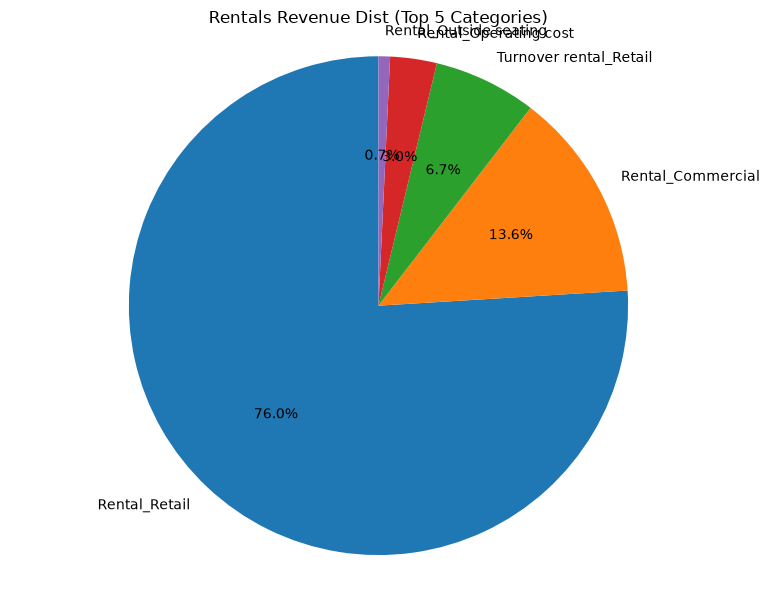

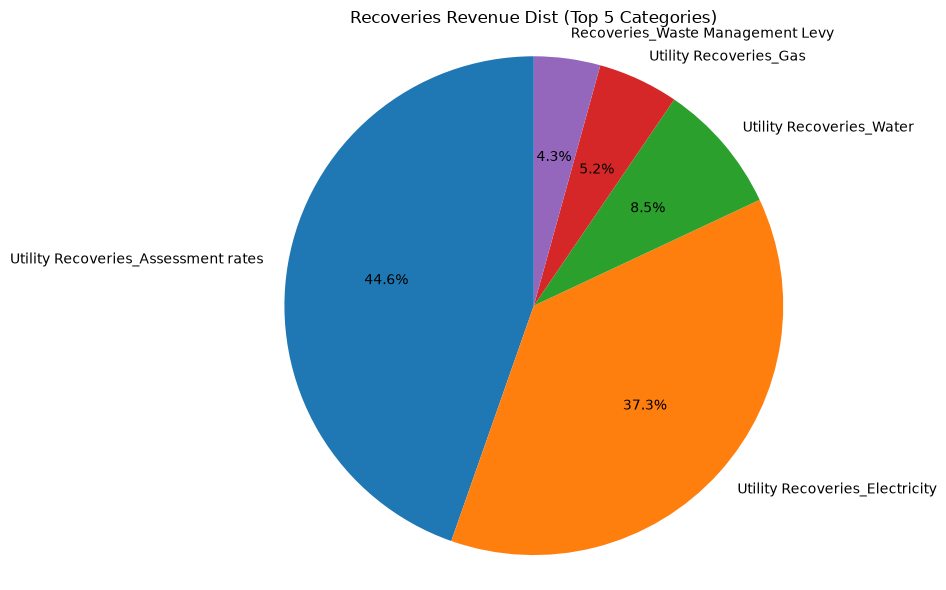

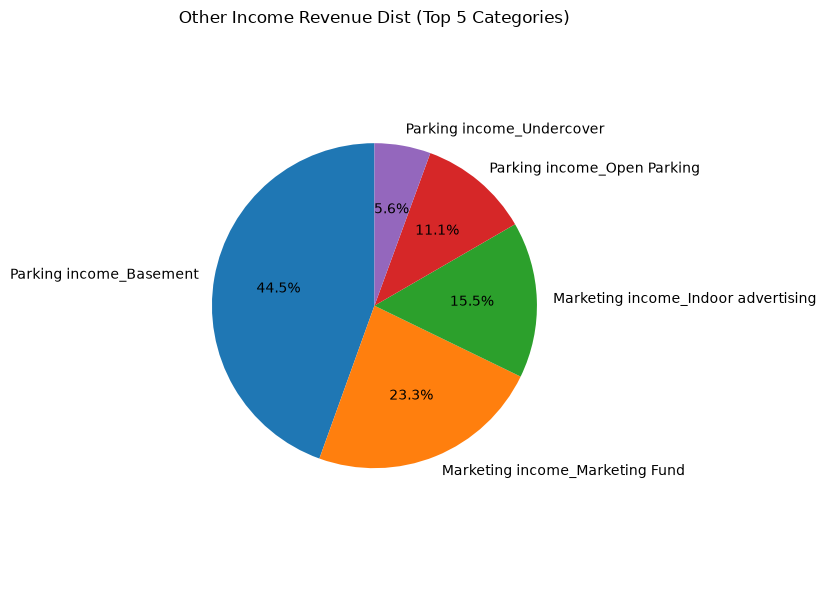

In [ ]:
#Top 5 income categories withing each group

import matplotlib.pyplot as plt

a1_categories = pd.read_sql_query(
    text("""
        WITH classified AS (
            SELECT
                "IncomeCategory",
                "TransactionAmount",
                CASE
                    WHEN "IncomeCategory" LIKE 'Rental_%'
                      OR "IncomeCategory" LIKE 'Turnover rental%'
                      OR "IncomeCategory" = 'Rebates & remissions_Rent'
                        THEN 'Rentals'
                    WHEN "IncomeCategory" LIKE 'Recoveries_%'
                      OR "IncomeCategory" LIKE 'Utility Recoveries_%'
                        THEN 'Recoveries'
                    WHEN "IncomeCategory" LIKE 'Parking income_%'
                      OR "IncomeCategory" LIKE 'Marketing income_%'
                      OR "IncomeCategory" LIKE 'Other income_%'
                      OR "IncomeCategory" LIKE 'Fee income_%'
                      OR "IncomeCategory" LIKE 'Penalty receive_%'
                      OR "IncomeCategory" LIKE 'Body corporate levies received_%'
                      OR "IncomeCategory" LIKE 'Bad debts recovered_%'
                      OR "IncomeCategory" LIKE 'Lease cancellation fee_%'
                        THEN 'Other Income'
                END AS income_group
            FROM "TenantLedger"
            WHERE "IncomeCategory" <> 'Tenant Deposits'
        ),
        category_totals AS (
            SELECT income_group, "IncomeCategory",
                   SUM("TransactionAmount") AS total_income
            FROM classified
            WHERE income_group IS NOT NULL
            GROUP BY income_group, "IncomeCategory"
        ),
        ranked AS (
            SELECT *,
                   ROW_NUMBER() OVER (
                       PARTITION BY income_group
                       ORDER BY total_income DESC
                   ) AS category_rank
            FROM category_totals
        )
        SELECT income_group, "IncomeCategory", total_income
        FROM ranked
        WHERE category_rank <= 5
        ORDER BY income_group, category_rank
    """),
    engine
)

print(a1_categories.to_string(index=False))



groups = ["Rentals", "Recoveries", "Other Income"]

for group in groups:
    data = a1_categories[
        a1_categories["income_group"] == group
    ].copy()

    plt.figure(figsize=(8, 6))

    plt.pie(
        data["total_income"],
        labels=data["IncomeCategory"],
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title(f"{group} Revenue Distribution (Top 5 Categories)")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

A2 Solution

In [94]:
#Tenant Turn over analysis

columns = pd.read_sql_query(
    text("""
        SELECT table_name, column_name, data_type
        FROM information_schema.columns
        WHERE table_schema = 'public'
          AND table_name IN (
              'TurnoverHistory',
              'TurnoverTypes',
              'Tenants',
              'Properties'
          )
        ORDER BY table_name, ordinal_position
    """),
    engine
)

print(columns.to_string(index=False))



     table_name             column_name                   data_type
     Properties              PropertyID                        text
     Properties            PropertyName                        text
     Properties                    City                        text
     Properties             LastUpdated                        text
        Tenants              PropertyID                        text
        Tenants                TenantID                        text
        Tenants          PropertyUnitID                        text
        Tenants              TenantName                        text
        Tenants          OccupantStatus                        text
        Tenants          LeaseStartDate timestamp without time zone
        Tenants     TenantOccupancyDate timestamp without time zone
        Tenants         LeaseExpiryDate timestamp without time zone
        Tenants         LeaseVacateDate timestamp without time zone
        Tenants         PrintStatements         

In [95]:
#What does JV0005 identify in the database

check_jv = pd.read_sql_query(
    text("""
        SELECT 'Properties.PropertyID' AS field, COUNT(*) AS matches
        FROM "Properties"
        WHERE "PropertyID" = 'JV0005'

        UNION ALL

        SELECT 'Tenants.TenantID', COUNT(*)
        FROM "Tenants"
        WHERE "TenantID" = 'JV0005'

        UNION ALL

        SELECT 'Tenants.TenantGroupID', COUNT(*)
        FROM "Tenants"
        WHERE "TenantGroupID" = 'JV0005'

        UNION ALL

        SELECT 'TurnoverHistory.PropertyID', COUNT(*)
        FROM "TurnoverHistory"
        WHERE "PropertyID" = 'JV0005'
    """),
    engine
)

print(check_jv.to_string(index=False))

                     field  matches
     Properties.PropertyID        1
          Tenants.TenantID        0
     Tenants.TenantGroupID        0
TurnoverHistory.PropertyID      435


In [96]:
#Now retrieve the monthly turnover by tenant 
a2 = pd.read_sql_query(
    text("""
        SELECT
            t."TenantID",
            t."TenantName",
            t."StoreCategoryID",
            th."TurnoverTypeID",
            tt."TurnoverType",
            th."Period",
            SUM(th."Amount") AS total_turnover
        FROM "TurnoverHistory" th
        JOIN "Tenants" t
          ON t."TenantID" = th."TenantID"
         AND t."PropertyID" = th."PropertyID"
        LEFT JOIN "TurnoverTypes" tt
          ON tt."TurnoverTypeID" = th."TurnoverTypeID"
        WHERE th."PropertyID" = 'JV0005'
          AND th."ReportTypeID" = 'RPT'
        GROUP BY
            t."TenantID",
            t."TenantName",
            t."StoreCategoryID",
            th."TurnoverTypeID",
            tt."TurnoverType",
            th."Period"
        ORDER BY th."Period", t."TenantName"
    """),
    engine
)

print(a2.head(15).to_string(index=False))
print("Rows:", len(a2))

TenantID                      TenantName StoreCategoryID TurnoverTypeID         TurnoverType  Period  total_turnover
  731101 Bahringer, Tremblay and Kessler              18          SD018          Coffee Shop  202501       343583.62
  860801            Bartoletti-Cummerata              64          SD064   Sports Wear & Eq C  202501       656256.87
  729501                Baumbach-Farrell              21          SD021 Dept Store 2(F/AP/H)  202501       734709.50
  729101                   Bechtelar LLC              41          SD041  Hardware & Security  202501       144915.50
  734801             Bechtelar-Considine              33          SD033      Food Speciality  202501       269334.00
  731401                 Becker-Schulist              60          SD060     Restaurant & Bar  202501      3309589.87
  733101   Becker, Weissnat and Prosacco              22          SD022           Drive Thru  202501      1607687.00
  730301  Bednar, Kessler and Altenwerth              57        

In [99]:
#Store-category look up

tables = pd.read_sql_query(
    text("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = 'public'
          AND table_type = 'BASE TABLE'
        ORDER BY table_name
    """),
    engine
)

print(tables.to_string(index=False))

         table_name
         Properties
PropertyUnitHistory
      PropertyUnits
       TenantGroups
       TenantLedger
            Tenants
    TurnoverHistory
      TurnoverTypes


In [100]:
#Aggregatee monthly turnover

a2_monthly = (
    a2.groupby(["Period", "TurnoverType"], as_index=False)
       ["total_turnover"].sum()
)

a2_pivot = a2_monthly.pivot(
    index="Period",
    columns="TurnoverType",
    values="total_turnover"
).fillna(0)

print(a2_pivot.head())

TurnoverType  Beauty Salon/Spa      Books  Bottle Stores  Coffee Shop  \
Period                                                                  
202501               720721.00  522792.09     2485847.92    808063.45   
202502               627316.00  433048.66     2390476.74    827542.20   
202503               707753.00  511592.90     3329202.54    912279.30   
202504               654399.00  550975.71     2812420.22    840149.35   
202505               685079.16  463537.97     2576631.05    926405.53   

TurnoverType  Dept Store 2(F/AP/H)  Drive Thru  Dry Cleaning&Repairs  \
Period                                                                 
202501                   734709.50  5616175.87             102185.19   
202502                   655946.04  5157882.69              74880.87   
202503                   759911.07  5575825.15             107795.37   
202504                   793524.14  5379586.34              97944.36   
202505                   859811.94  6405900.21          

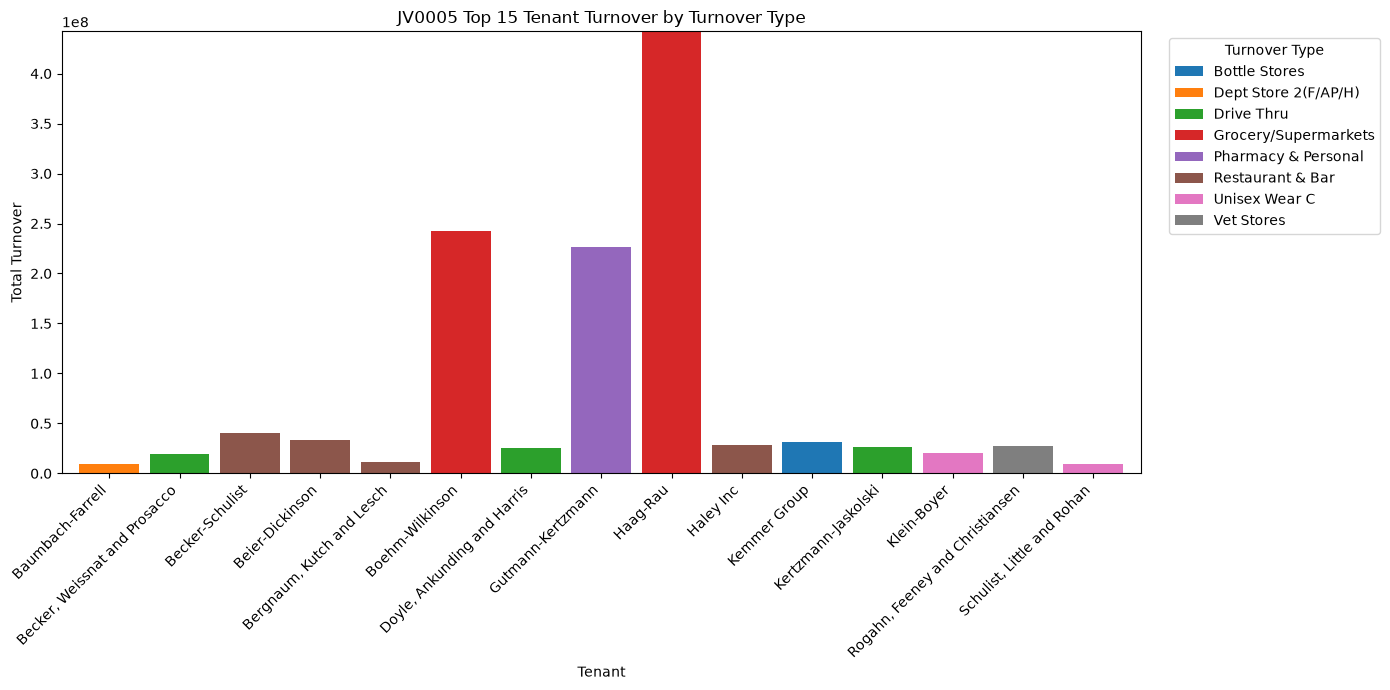

In [108]:
#Create chart 


import matplotlib.pyplot as plt

# Total turnover per tenant and turnover type
a2_tenant = (
    a2.groupby(["TenantName", "TurnoverType"], as_index=False)
      ["total_turnover"].sum()
)

# Select top 15 tenants
top_tenants = (
    a2_tenant.groupby("TenantName")["total_turnover"]
    .sum()
    .nlargest(15)
    .index
)

a2_top = a2_tenant[
    a2_tenant["TenantName"].isin(top_tenants)
]

a2_pivot = a2_top.pivot(
    index="TenantName",
    columns="TurnoverType",
    values="total_turnover"
).fillna(0)

ax = a2_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    width=0.85
)

ax.set_title("JV0005 Top 15 Tenant Turnover by Turnover Type")
ax.set_xlabel("Tenant")
ax.set_ylabel("Total Turnover")
ax.legend(title="Turnover Type", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [109]:
#Which categories perform best
#Store category performance

a2_store_category = (
    a2.groupby("StoreCategoryID", as_index=False)
      ["total_turnover"].sum()
      .sort_values("total_turnover", ascending=False)
)

print(a2_store_category.head(10).to_string(index=False))

StoreCategoryID  total_turnover
             38    684856437.41
             57    235768008.16
             60    125608977.60
             22     70865383.61
             09     37312303.18
             74     36014960.26
             77     27808941.85
             18     10538788.41
             21      9859582.87
             64      8922252.78


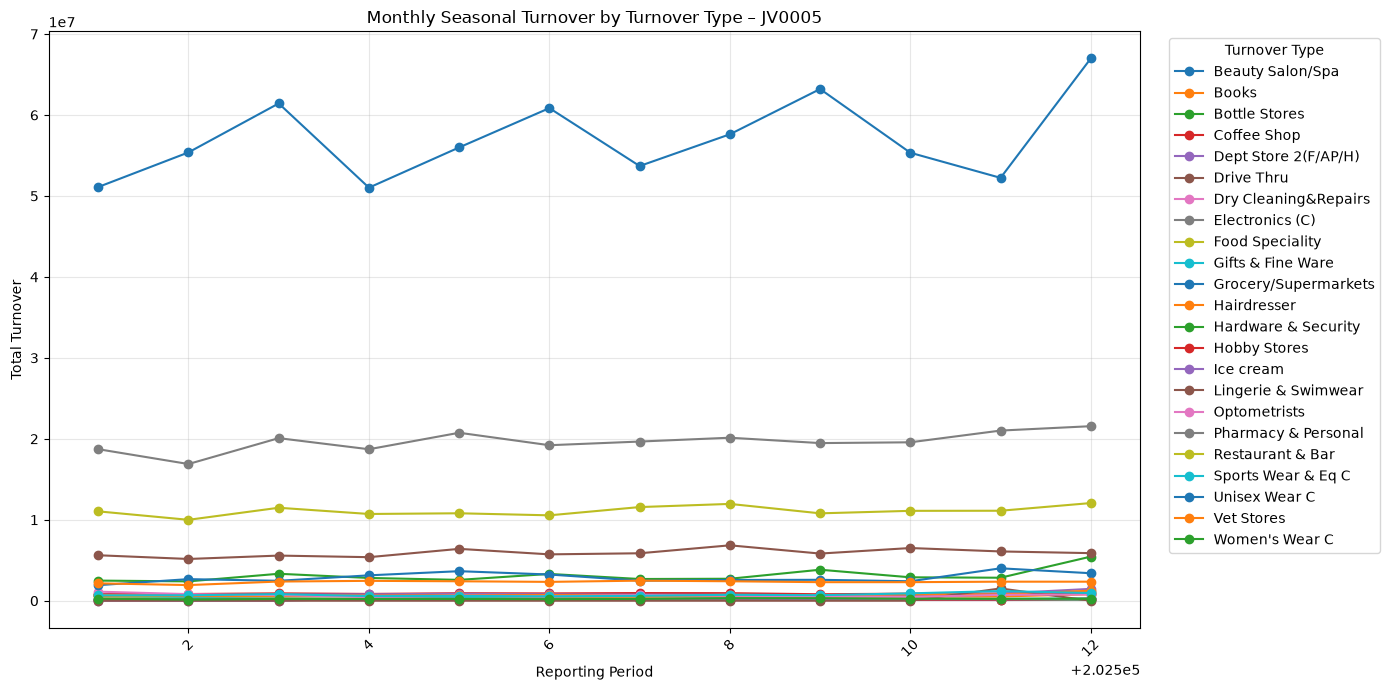

In [110]:
#Monthly seasonal turnover by turnover type

a2_monthly = (
    a2.groupby(["Period", "TurnoverType"], as_index=False)
      ["total_turnover"].sum()
)

a2_monthly_pivot = a2_monthly.pivot(
    index="Period",
    columns="TurnoverType",
    values="total_turnover"
).fillna(0)

ax = a2_monthly_pivot.plot(
    kind="line",
    marker="o",
    figsize=(14, 7)
)

ax.set_title("Monthly Seasonal Turnover by Turnover Type – JV0005")
ax.set_xlabel("Reporting Period")
ax.set_ylabel("Total Turnover")
ax.legend(title="Turnover Type", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A2 – Turnover Analysis for JV0005
The analysis shows that Store Category 38 generated the highest total turnover at approximately 684.86 million, followed by Category 57 at 235.77 million and Category 60 at 125.61 million. Category 38 significantly outperformed the other categories.

The monthly turnover analysis by turnover type shows that Beauty Salon/Spa generated the highest turnover throughout the year, peaking in December at approximately 67 million. Electronics (C) maintained relatively stable turnover, while Food Speciality also showed consistent performance. Beauty Salon/Spa experienced noticeable increases around March, June, September and December, suggesting recurring seasonal patterns.

Overall, the results indicate that turnover performance is concentrated in a few store categories and turnover types, with Beauty Salon/Spa being the strongest turnover type.

A3 Solution

In [102]:
#Confirm the tenant ledger date and trasactions

ledger_columns = pd.read_sql_query(
    text("""
        SELECT column_name, data_type
        FROM information_schema.columns
        WHERE table_schema = 'public'
          AND table_name = 'TenantLedger'
        ORDER BY ordinal_position
    """),
    engine
)

print(ledger_columns.to_string(index=False))


        column_name                   data_type
      TransactionID                        text
         PropertyID                        text
           TenantID                        text
    TransactionDate timestamp without time zone
     IncomeCategory                        text
    TransactionType                        text
  TransactionAmount            double precision
   ReceiptReference                        text
            BatchID                        text
          TaxAmount                        text
             Period                      bigint
           Currency                        text
        ReceiptCode                        text
      TaxRecordDate timestamp without time zone
            DueDate timestamp without time zone
TransactionFromDate timestamp without time zone
  TransactionToDate timestamp without time zone
        LastUpdated                        text


In [103]:
#Distinguish billed amounts from actual collections correctly
a3_types = pd.read_sql_query(
    text("""
        SELECT
            "TransactionType",
            COUNT(*) AS transactions,
            SUM("TransactionAmount") AS total_amount
        FROM "TenantLedger"
        WHERE "IncomeCategory" <> 'Tenant Deposits'
        GROUP BY "TransactionType"
        ORDER BY "TransactionType"
    """),
    engine
)

print(a3_types.to_string(index=False))


TransactionType  transactions  total_amount
   CashReceipts         30012 -4.066821e+08
        Charges         39368  4.977681e+08
    CreditNotes          4038 -7.393693e+07
    PrePayments           630  8.118360e+06
         Refund             8  6.339337e+04
       WriteOff            18 -2.522587e+06


In [ ]:
#calculate tenant monthly ratio

a3 = pd.read_sql_query(
    text("""
        WITH tenant_monthly AS (
            SELECT
                tl."PropertyID",
                tl."TenantID",
                tl."Period",

                SUM(
                    CASE
                        WHEN tl."TransactionType" = 'Charges'
                            THEN tl."TransactionAmount"
                        WHEN tl."TransactionType" = 'CreditNotes'
                            THEN tl."TransactionAmount"
                        ELSE 0
                    END
                ) AS billed_amount,

                SUM(
                    CASE
                        WHEN tl."TransactionType" = 'CashReceipts'
                            THEN -tl."TransactionAmount"
                        WHEN tl."TransactionType" = 'Refund'
                            THEN -tl."TransactionAmount"
                        ELSE 0
                    END
                ) AS collected_amount

            FROM "TenantLedger" tl
            WHERE tl."IncomeCategory" <> 'Tenant Deposits'
            GROUP BY
                tl."PropertyID",
                tl."TenantID",
                tl."Period"
        ),

        tenant_ratios AS (
            SELECT
                "PropertyID",
                "TenantID",
                "Period",
                LEAST(
                    100.0,
                    collected_amount / NULLIF(billed_amount, 0) * 100
                ) AS collection_ratio
            FROM tenant_monthly
            WHERE billed_amount > 0
        )

        SELECT
            p."PropertyName" AS building,
            tr."Period",
            ROUND(AVG(tr.collection_ratio)::numeric, 2)
                AS average_collection_ratio
        FROM tenant_ratios tr
        JOIN "Properties" p
          ON p."PropertyID" = tr."PropertyID"
        GROUP BY
            p."PropertyName",
            tr."Period"
        ORDER BY
            tr."Period",
            building
    """),
    engine
)

print(a3.head(15).to_string(index=False))
print("Total rows:", len(a3))
print("Buildings:", a3["building"].nunique())



                       building  Period  average_collection_ratio
                Estuary Offices  202501                     50.00
Glenelly Mansion Corporate Park  202501                     53.96
     Hazel Luxury Retail Centre  202501                     74.88
        Palm Dune Retail Centre  202501                     73.74
             Park Ridge Offices  202501                     69.71
        Rivery Lifestyle Centre  202501                     31.41
           Rivery Retail Centre  202501                     76.36
        The Docks Retail Centre  202501                     72.14
      The Ravine Corporate Park  202501                     79.48
                Estuary Offices  202502                     56.93
Glenelly Mansion Corporate Park  202502                     51.79
     Hazel Luxury Retail Centre  202502                     66.09
        Palm Dune Retail Centre  202502                     72.02
             Park Ridge Offices  202502                     53.73
        Ri

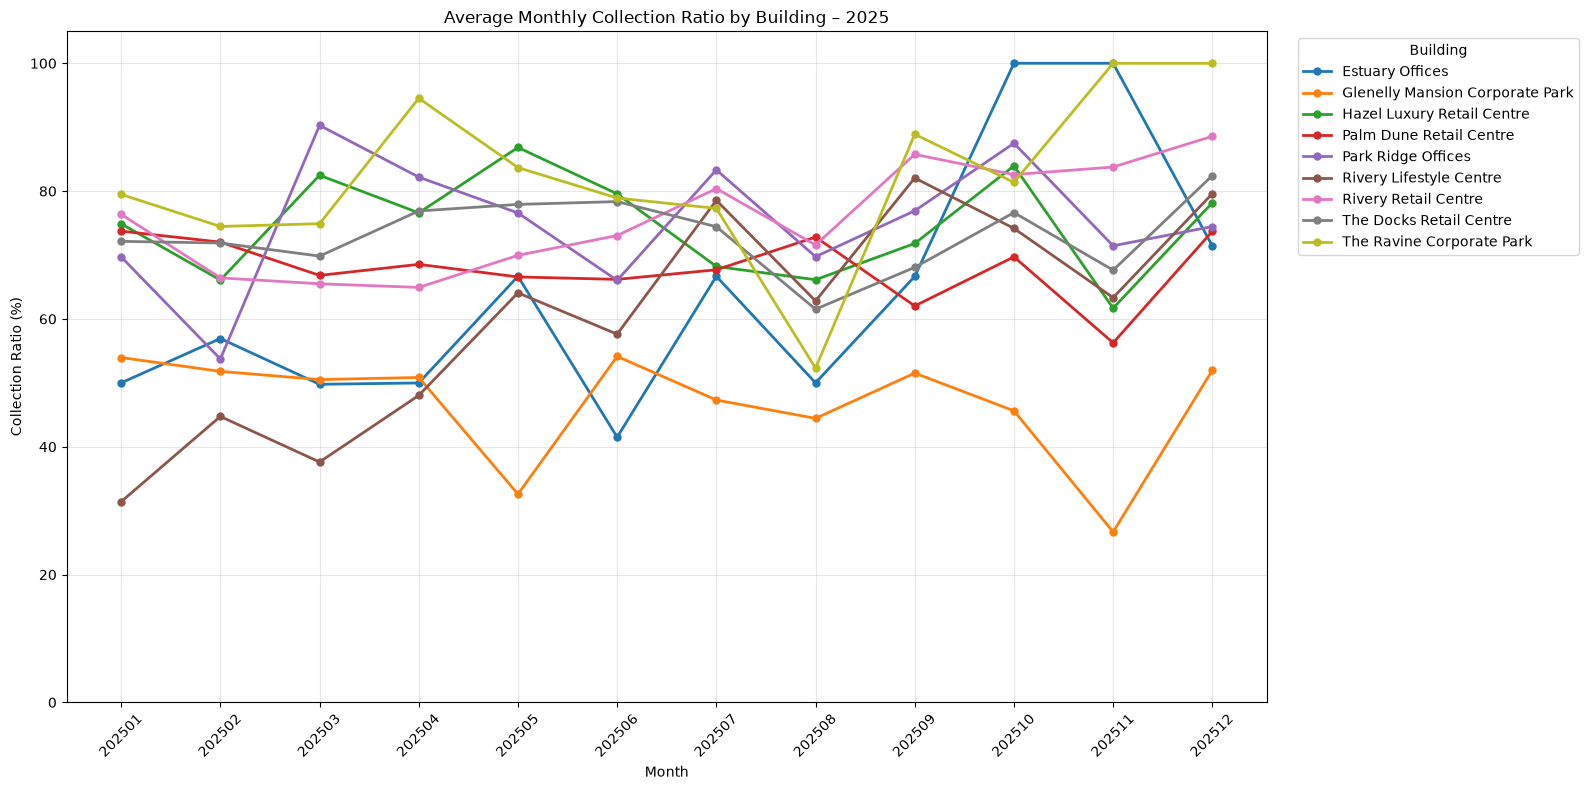

In [107]:
import matplotlib.pyplot as plt

a3_pivot = a3.pivot(
    index="Period",
    columns="building",
    values="average_collection_ratio"
).sort_index()

fig, ax = plt.subplots(figsize=(16, 8))

for building in a3_pivot.columns:
    ax.plot(
        a3_pivot.index.astype(str),
        a3_pivot[building],
        marker="o",
        linewidth=2,
        markersize=5,
        label=building
    )

ax.set_title("Average Monthly Collection Ratio by Building – 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Collection Ratio (%)")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

ax.legend(
    title="Building",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()